# E-Commerce Analysis with Python (pandas)

The same business questions as the SQL case study (`sql/02_analysis_queries.sql`), answered with pandas. Each section shows the SQL idea it matches, so the two can be compared side by side.

**Data:** 100 customers, 8 products, 200 orders, 519 order lines (Mar 2023 – Feb 2024).

## 1. Setup and load data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'font.family': 'Arial'})
BLUE, ORANGE = '#2a78d6', '#eb6834'

customers = pd.read_csv('../data/customers.csv')
products  = pd.read_csv('../data/products.csv')
orders    = pd.read_csv('../data/orders.csv', parse_dates=['order_date'])
details   = pd.read_csv('../data/orderdetails.csv')

for name, df in [('customers', customers), ('products', products), ('orders', orders), ('orderdetails', details)]:
    print(f'{name:<13} {df.shape[0]:>4} rows  {df.shape[1]} columns')

customers      100 rows  3 columns
products         8 rows  4 columns
orders         200 rows  4 columns
orderdetails   519 rows  4 columns


In [2]:
orders.head()

,order_id,order_date,customer_id,total_amount
0,1,2023-09-27,67,45000
1,2,2023-11-19,98,16000
2,3,2023-12-20,46,260000
3,4,2023-04-29,83,27000
4,5,2023-04-05,99,221000


## 2. Data quality checks
Before analysis: missing values, duplicates, broken keys, and whether order totals add up.

In [3]:
print('Missing values:', sum(df.isna().sum().sum() for df in [customers, products, orders, details]))
print('Duplicate order lines:', details.duplicated().sum())
print('Orders with unknown customer:', (~orders['customer_id'].isin(customers['customer_id'])).sum())
print('Lines with unknown product  :', (~details['product_id'].isin(products['product_id'])).sum())

details['line_amount'] = details['quantity'] * details['price_per_unit']
line_totals = details.groupby('order_id')['line_amount'].sum()
mismatch = (orders.set_index('order_id')['total_amount'] != line_totals).sum()
print('Orders whose total != sum of lines:', mismatch)

Missing values: 0
Duplicate order lines: 24
Orders with unknown customer: 0
Lines with unknown product  : 0
Orders whose total != sum of lines: 0


The 24 repeated order lines are real (the order totals include them), so they are kept - the same decision as in the MySQL schema.

## 3. One joined table
Like the SQL view `vw_order_lines`: every order line with its customer and product.

In [4]:
lines = (details.merge(orders, on='order_id')
                .merge(customers.rename(columns={'name': 'customer_name'}), on='customer_id')
                .merge(products.rename(columns={'name': 'product_name'}), on='product_id'))
lines['month'] = lines['order_date'].dt.strftime('%Y-%m')
lines.head(3)

,order_id,product_id,quantity,price_per_unit,line_amount,order_date,customer_id,total_amount,customer_name,location,product_name,category,price,month
0,1,1,3,15000,45000,2023-09-27,67,45000,Renee Korpal,Lucknow,"Smartphone 6""",Electronics,15000,2023-09
1,2,3,2,8000,16000,2023-11-19,98,16000,Aniruddh Arya,Jaipur,Bluetooth Headphones,Electronics,8000,2023-11
2,3,2,1,60000,60000,2023-12-20,46,260000,Kismat Bajwa,Delhi,"Laptop 15"" Pro",Electronics,60000,2023-12


## 4. Customer insights

**Q1. Top 3 cities by number of customers** — SQL: `GROUP BY location ORDER BY COUNT(*) DESC LIMIT 3`

In [5]:
customers['location'].value_counts().head(3)

location
Delhi      16
Chennai    15
Jaipur     11
Name: count, dtype: int64

**Q2. How many orders does each customer place?** — SQL: CTE + `GROUP BY number_of_orders`

In [6]:
orders_per_customer = orders.groupby('customer_id').size()
segment = pd.cut(orders_per_customer, bins=[0, 1, 4, 100],
                 labels=['One-time buyer', 'Occasional shopper (2-4)', 'Regular customer (5+)'])
print(segment.value_counts())
print('Never ordered:', len(customers) - orders_per_customer.size)

Occasional shopper (2-4)    50
One-time buyer              26
Regular customer (5+)        8
Name: count, dtype: int64
Never ordered: 16


**Q4. Top 5 customers by spend**

In [7]:
(orders.groupby('customer_id')
       .agg(total_orders=('order_id', 'count'), total_spent=('total_amount', 'sum'))
       .nlargest(5, 'total_spent')
       .join(customers.set_index('customer_id')))

,total_orders,total_spent,name,location
customer_id,,,,
32,6,889000,Romil Bora,Chennai
17,4,864000,Rhea Issac,Jaipur
51,5,713000,Indrans Lanka,Lucknow
24,4,693000,Samar Sharaf,Mumbai
100,3,613000,Kimaya Sur,Bangalore


**Q5. Revenue by city**

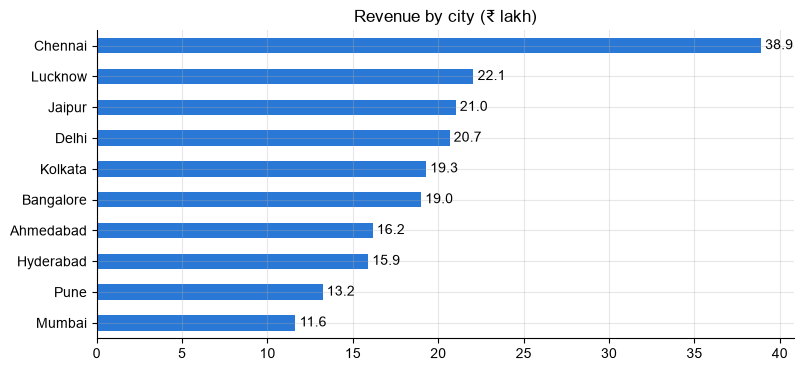

In [8]:
city = lines.groupby('location')['line_amount'].sum().sort_values()
ax = city.div(1e5).plot.barh(color=BLUE, title='Revenue by city (₹ lakh)')
ax.bar_label(ax.containers[0], fmt='%.1f', padding=3); ax.set_ylabel('');

## 5. Product analysis

**Q6. Products with average quantity 2 per order, by revenue** — SQL: `HAVING AVG(quantity) = 2`

In [9]:
prod = lines.groupby('product_name').agg(avg_quantity=('quantity', 'mean'),
                                          units_sold=('quantity', 'sum'),
                                          revenue=('line_amount', 'sum'))
prod[prod['avg_quantity'] == 2].sort_values('revenue', ascending=False)

,avg_quantity,units_sold,revenue
product_name,,,
"Smartphone 6""",2.0,108,1620000
Wireless Earbuds,2.0,130,390000


**Q7–Q8. Category reach and revenue share**

In [10]:
cat = lines.groupby('category').agg(unique_customers=('customer_id', 'nunique'),
                                   units_sold=('quantity', 'sum'),
                                   revenue=('line_amount', 'sum'))
cat['revenue_share_%'] = (cat['revenue'] / cat['revenue'].sum() * 100).round(2)
cat.sort_values('revenue', ascending=False)

,unique_customers,units_sold,revenue,revenue_share_%
category,,,,
Electronics,79,633,12758000,64.49
Photography,45,151,6040000,30.53
Wearable Tech,61,249,985000,4.98


**Q9. Product ranking** — SQL: `RANK() OVER (ORDER BY revenue DESC)`

In [11]:
prod['revenue_rank'] = prod['revenue'].rank(ascending=False, method='min').astype(int)
prod.sort_values('revenue_rank')

,avg_quantity,units_sold,revenue,revenue_rank
product_name,,,,
"Laptop 15"" Pro",1.880597,126,7560000,1
Digital SLR Camera,1.935897,151,6040000,2
"Smartphone 6""",2.000000,108,1620000,3
E-Book Reader,1.911765,130,1560000,4
Bluetooth Headphones,1.985294,135,1080000,5
Portable Bluetooth Speaker,2.271186,134,938000,6
Smartwatch Fitness Tracker,1.983333,119,595000,7
Wireless Earbuds,2.000000,130,390000,8


## 6. Sales trends

**Q10–Q13. Monthly sales, % change, AOV and running total** — SQL: `LAG()` and `SUM() OVER`

In [12]:
monthly = (orders.assign(month=orders['order_date'].dt.strftime('%Y-%m'))
                 .groupby('month')
                 .agg(orders=('order_id', 'count'), sales=('total_amount', 'sum'), aov=('total_amount', 'mean')))
monthly['pct_change'] = (monthly['sales'].pct_change() * 100).round(2)   # LAG()
monthly['running_total'] = monthly['sales'].cumsum()                       # SUM() OVER
monthly['aov'] = monthly['aov'].round(0)
monthly

,orders,sales,aov,pct_change,running_total
month,,,,,
2023-03,13,789000,60692.0,NaN,789000
2023-04,21,1704000,81143.0,115.97,2493000
2023-05,18,1582000,87889.0,-7.16,4075000
2023-06,10,1040000,104000.0,-34.26,5115000
2023-07,26,2568000,98769.0,146.92,7683000
2023-08,16,1800000,112500.0,-29.91,9483000
2023-09,24,2927000,121958.0,62.61,12410000
2023-10,18,1497000,83167.0,-48.86,13907000
2023-11,12,1151000,95917.0,-23.11,15058000


Top 3 months:
month
2023-09    2927000
2023-12    2774000
2023-07    2568000
Name: sales, dtype: int64


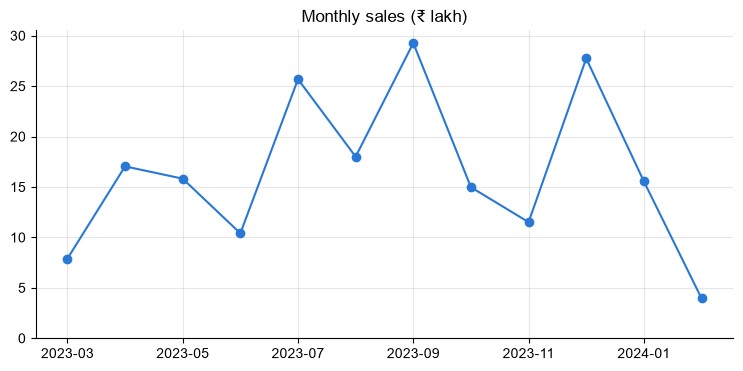

In [13]:
ax = monthly['sales'].div(1e5).plot(marker='o', color=BLUE, title='Monthly sales (₹ lakh)')
ax.set_xlabel(''); ax.set_ylim(0);
print('Top 3 months:'); print(monthly['sales'].nlargest(3))

**Q14. New customers per month**

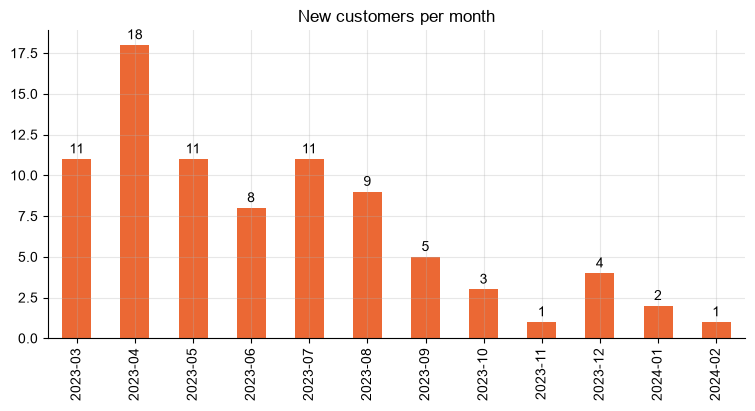

In [14]:
first_month = orders.groupby('customer_id')['order_date'].min().dt.strftime('%Y-%m')
new_cust = first_month.value_counts().sort_index()
ax = new_cust.plot.bar(color=ORANGE, title='New customers per month')
ax.bar_label(ax.containers[0], padding=2); ax.set_xlabel('');

## 7. Inventory

**Q15–Q16. Sales frequency and low-engagement products (< 40% of customers)**

In [15]:
inv = lines.groupby('product_name').agg(order_lines=('order_id', 'count'),
                                         unique_customers=('customer_id', 'nunique'))
inv['reach_%'] = inv['unique_customers'] / len(customers) * 100
print('Top 5 by sales frequency:'); print(inv.nlargest(5, 'order_lines'))
print('\nLow engagement (< 40% of customers):'); print(inv[inv['reach_%'] < 40])

Top 5 by sales frequency:
                      order_lines  unique_customers  reach_%
product_name                                                
Digital SLR Camera             78                45     45.0
Bluetooth Headphones           68                46     46.0
E-Book Reader                  68                47     47.0
Laptop 15" Pro                 67                41     41.0
Wireless Earbuds               65                38     38.0

Low engagement (< 40% of customers):
                  order_lines  unique_customers  reach_%
product_name                                            
Smartphone 6"              54                36     36.0
Wireless Earbuds           65                38     38.0


## 8. RFM segmentation
Recency (days since last order), Frequency (orders), Monetary (spend), each scored 1–4. Same rules as the SQL view `vw_customer_rfm` (NTILE(4) with customer_id as tie-breaker).

In [16]:
last_date = orders['order_date'].max()
rfm = orders.groupby('customer_id').agg(last_order=('order_date', 'max'),
                                        frequency=('order_id', 'count'),
                                        monetary=('total_amount', 'sum')).reset_index()
rfm['recency_days'] = (last_date - rfm['last_order']).dt.days

def ntile(sorted_index, n=4):
    """Same as SQL NTILE(n): split the sorted rows into n equal buckets."""
    return pd.Series([i * n // len(sorted_index) + 1 for i in range(len(sorted_index))], index=sorted_index)

rfm['r_score'] = ntile(rfm.sort_values(['recency_days', 'customer_id'], ascending=[False, True]).index)
rfm['f_score'] = ntile(rfm.sort_values(['frequency', 'customer_id']).index)
rfm['m_score'] = ntile(rfm.sort_values(['monetary', 'customer_id']).index)

def segment(r):
    if r.r_score >= 3 and r.f_score >= 3 and r.m_score >= 3: return 'Champions'
    if r.r_score >= 3 and r.f_score >= 2: return 'Loyal / Potential'
    if r.r_score <= 2 and r.f_score >= 3: return 'At Risk'
    if r.r_score == 1: return 'Lost'
    return 'Needs Attention'

rfm['segment'] = rfm.apply(segment, axis=1)
summary = rfm.groupby('segment').agg(customers=('customer_id', 'count'), revenue=('monetary', 'sum'))
summary['revenue_share_%'] = (summary['revenue'] / summary['revenue'].sum() * 100).round(2)
summary.sort_values('revenue', ascending=False)

,customers,revenue,revenue_share_%
segment,,,
Champions,23,10440000,52.77
Needs Attention,20,3421000,17.29
At Risk,13,2717000,13.73
Lost,16,1764000,8.92
Loyal / Potential,12,1441000,7.28


## 9. Cohort retention
Cohort = month of first order. Each cell = % of that cohort that ordered again N months later.

In [17]:
o = orders.copy()
o['order_month'] = o['order_date'].dt.to_period('M')
o['cohort'] = o.groupby('customer_id')['order_month'].transform('min')
o['month_number'] = (o['order_month'] - o['cohort']).apply(lambda d: d.n)
cohort = o.groupby(['cohort', 'month_number'])['customer_id'].nunique().unstack()
retention = (cohort.div(cohort[0], axis=0) * 100).round(0)
retention.iloc[:, :7]

month_number,0,1,2,3,4,5,6
cohort,,,,,,,
2023-03,100.0,9.0,9.0,NaN,27.0,NaN,27.0
2023-04,100.0,33.0,11.0,17.0,6.0,28.0,11.0
2023-05,100.0,NaN,NaN,27.0,36.0,18.0,9.0
2023-06,100.0,25.0,NaN,25.0,25.0,12.0,25.0
2023-07,100.0,18.0,9.0,45.0,NaN,27.0,27.0
2023-08,100.0,22.0,11.0,11.0,11.0,11.0,NaN
2023-09,100.0,NaN,20.0,NaN,NaN,20.0,NaN
2023-10,100.0,NaN,33.0,NaN,NaN,NaN,NaN
2023-11,100.0,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
repeat = (orders.groupby('customer_id').size() > 1)
print(f'Repeat purchase rate: {repeat.mean():.1%} of buying customers ordered more than once')

Repeat purchase rate: 69.0% of buying customers ordered more than once


## 10. Key findings

- **Revenue ₹1.98 Cr** from 200 orders; average order value ≈ ₹98,915.
- **Electronics = 64.5% of revenue**; Laptop and DSLR together ≈ 69%.
- **Chennai** is the top revenue city (₹38.9 L); Delhi has the most customers.
- **23 Champion customers bring 52.8% of revenue** – protect them with loyalty benefits.
- **69% repeat rate**, but **new-customer acquisition fell** from 18 in Apr 2023 to 1–4 a month after Oct 2023.
- **16 customers never ordered** – target them with a first-order offer.

All numbers match the MySQL results in `results/query_results.md`.